# Credit Scoring - walkthrough (Project 1)

## 1. Learning objectives
After this notebook you can:
1. Turn raw application fields into **business features** (loan-to-income, EMI, debt-service ratio) and check each one **by hand**.
2. Handle **missing income** with a median imputer + a missing-indicator **inside a Pipeline** (so training and the API behave identically).
3. Show how **one leaky column** (`interest_rate_offered`) fakes a brilliant model, and how an honest model looks.
4. Evaluate a credit model with **ROC-AUC, Gini, KS, recall at a fixed approval rate** and read it as money.
5. Explain one decision with **reason codes** and audit it for **fairness** (adverse impact ratio).
6. Read a **KS drift test** correctly: drift is a *signal*, not an order to retrain.

Course map: DATA -> FEATURE ENGINEERING -> TRAINING -> (MLflow) -> REGISTRY -> DEPLOYMENT -> MONITORING -> DRIFT -> RETRAINING.

## 2. Business problem
A retail bank must decide, **when the application is submitted**, whether to approve an unsecured personal loan.
The model returns the **probability of default within 12 months (PD)**.

| PD band | Decision hint | Who acts |
|---|---|---|
| LOW (< 10%) | APPROVE | system |
| MEDIUM (10% - 22%) | REFER_TO_UNDERWRITER | human underwriter |
| HIGH (>= 22%) | DECLINE | system (the applicant gets reason codes) |

Wrong decisions cost money in two directions: approving a defaulter loses ~60% of the loan; declining a good customer loses the ~8% margin.

## 3. Dataset description
`data/raw/applications.csv`: 12,000 synthetic applications (2022-2023, see `docs/DATASET.md`). Problems injected on purpose:
~12% missing `annual_income` (not at random: higher for self-employed / high earners), income outliers (extra zero typos),
a near-duplicate pair `annual_income` ~ `monthly_income`, `monthly_debt` ~ `debt_to_income_ratio`, ~11% defaulters (imbalance),
repeat applicants, **six leakage columns** (information from AFTER the decision), and **sensitive** columns (`gender`, `marital_status`).

Rule to repeat all semester: *"Would this information exist at the moment the application is submitted?"*

## 4. Why this concept is needed
A bank model is judged by three people: the **data scientist** (is it accurate?), the **risk/compliance officer** (is it fair and explainable?)
and the **ML engineer** (does it behave the same in production?). So this project is about feature *selection and governance* as much as accuracy:
every feature needs a definition, an owner, a prediction-time availability statement and an Approved / Rejected status (`configs/feature_registry.yaml`).

In [1]:
## 5. Imports
import os, sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # works from the project root or from notebooks/
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src.common.drift import ks_drift_report
from src.features.build_features import emi, engineer, time_split
from src.features.manual_examples import APPLICANT, hand_calculation
from src.features.registry import check_features_approved, load_registry, load_selected
from src.governance.fairness_audit import adverse_impact_ratio, group_table
from src.models.metrics import business_view, calibration_table, credit_metrics
from src.models.pipeline import build_pipeline
from src.models.reason_codes import reason_codes, standardized_coefficients
from src import project as P

pd.set_option("display.width", 150)
print("project root OK:", (ROOT / "src").is_dir())

project root OK: True


In [2]:
## 6. Load data  (generated by `python -m src.data.make_dataset`; created here if missing)
if not (ROOT / "data/raw/applications.csv").exists():
    from src.data.make_dataset import main as make_data
    make_data()
raw = pd.read_csv("data/raw/applications.csv")
print(raw.shape, "| default rate:", round(raw.default_12m.mean(), 3), "| repeat applications:", int(raw.applicant_id.duplicated().sum()))
raw.head(3).T.head(12)

(12000, 26) | default rate: 0.113 | repeat applications: 840


                               0           1           2
applicant_id             A001553     A002277     A002843
application_date      2022-01-01  2022-01-01  2022-01-01
age                           36          27          27
annual_income           733000.0    367000.0    520000.0
monthly_income           63300.0     30900.0     41800.0
employment_years            15.4         0.9         8.0
loan_amount             480000.0    125000.0    216000.0
loan_term_months              24          24          48
credit_history_years         5.8         9.0         9.0
bureau_score               754.0       700.0       767.0
existing_loans                 2           0           0
monthly_debt             31900.0      5300.0      5800.0

missing %: {'annual_income': 12.2, 'bureau_score': 8.1}
annual_income missing by employment_type: {'business': 0.218, 'gig': 0.062, 'salaried': 0.082, 'self_employed': 0.204}
income skew raw 20.8 -> after log1p 0.20
Spearman annual_income ~ monthly_income: 0.89 | monthly_debt ~ debt_to_income_ratio: 0.81 -> keep only ONE of each pair


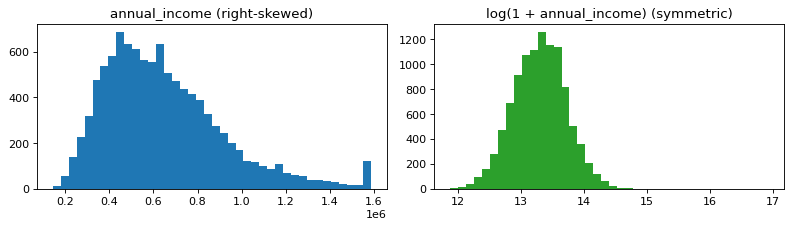

In [3]:
## 7. Explore: missing values, skew, imbalance, correlated pairs
print("missing %:", raw[["annual_income", "bureau_score"]].isna().mean().mul(100).round(1).to_dict())
print("annual_income missing by employment_type:", raw.assign(m=raw.annual_income.isna()).groupby("employment_type").m.mean().round(3).to_dict())
inc = raw.annual_income.dropna()
print(f"income skew raw {inc.skew():.1f} -> after log1p {np.log1p(inc).skew():.2f}")
num = raw[["annual_income", "monthly_income", "monthly_debt", "debt_to_income_ratio", "loan_amount"]]
print("Spearman annual_income ~ monthly_income:", round(num.corr("spearman").loc["annual_income", "monthly_income"], 2),
      "| monthly_debt ~ debt_to_income_ratio:", round(num.corr("spearman").loc["monthly_debt", "debt_to_income_ratio"], 2), "-> keep only ONE of each pair")
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(inc.clip(upper=inc.quantile(0.99)), bins=40); ax[0].set_title("annual_income (right-skewed)")
ax[1].hist(np.log1p(inc), bins=40, color="tab:green"); ax[1].set_title("log(1 + annual_income) (symmetric)")
plt.tight_layout(); plt.show()

## 8-9. Baseline and the concept that matters most: LEAKAGE
The honest baseline uses only information available at application time. The "leaky" version adds `interest_rate_offered`,
which the bank sets **after** its own risk scoring - so it is basically a copy of the answer.

In [4]:
## 8. Baseline (honest) vs leaky model on the SAME time-based split
full = engineer(raw)
tr, va, te = time_split(full)
honest = ["monthly_income", "employment_years", "loan_amount", "loan_term_months", "credit_history_years", "existing_loans",
          "monthly_debt", "number_of_dependents"]
def quick_auc(cols):
    m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))
    m.fit(tr[cols], tr.default_12m)
    return round(roc_auc_score(te.default_12m, m.predict_proba(te[cols])[:, 1]), 3)
print("honest baseline AUC (test)         :", quick_auc(honest))
print("+ interest_rate_offered (LEAKAGE)  :", quick_auc(honest + ["interest_rate_offered"]), "  <- too good to be true")
print("+ days_past_due_after_disbursal    :", quick_auc(honest + ["days_past_due_after_disbursal"]), "  <- the future in a column")

honest baseline AUC (test)         : 0.738
+ interest_rate_offered (LEAKAGE)  : 0.931   <- too good to be true
+ days_past_due_after_disbursal    : 1.0   <- the future in a column


In [5]:
## 10. Manual calculation first: the EMI of the example applicant (14% p.a., 24 months, 300,000)
a = APPLICANT
r = 0.14 / 12
growth = (1 + r) ** 24
by_hand = a["loan_amount"] * r * growth / (growth - 1)
print(f"r = {r:.6f}   (1+r)^24 = {growth:.5f}   EMI by hand = {by_hand:,.2f}   |   emi() = {float(emi(300000, 24)):,.2f}")
h = hand_calculation()["features"]
code_row = engineer(pd.DataFrame([APPLICANT])).iloc[0]
pd.DataFrame({"by_hand": {k: v for k, v in h.items()}, "engineer()": {k: code_row[k] for k in h}})

r = 0.011667   (1+r)^24 = 1.32099   EMI by hand = 14,403.86   |   emi() = 14,403.86


                            by_hand    engineer()
debt_to_income_ratio            0.2           0.2
log_income                13.304687     13.304687
loan_to_income                  0.5           0.5
emi_estimate           14403.864981  14403.864981
emi_to_income              0.288077      0.288077
debt_service_ratio         0.488077      0.488077
income_missing                    0             0
employment_stability           1_3y          1_3y
credit_history_bucket   established   established
city_tier                     tier1         tier1

In [6]:
## 11. Feature engineering + missing income handled INSIDE a Pipeline
selected = load_selected()
check_features_approved(selected)                       # governance guard: refuse unapproved / sensitive / leaky features
print(len(selected), "selected features:", selected)
reg = load_registry()
pd.DataFrame([(f, reg[f]["status"], reg[f]["prediction_time_availability"][:40]) for f in selected],
             columns=["feature", "status", "available at prediction time"]).head(8)

9 selected features: ['employment_years', 'loan_amount', 'credit_history_years', 'bureau_score', 'existing_loans', 'debt_to_income_ratio', 'employment_type', 'log_income', 'loan_to_income']


                feature    status              available at prediction time
0      employment_years  Approved   YES - collected on the application form
1           loan_amount  Approved   YES - collected on the application form
2  credit_history_years  Approved  YES - bureau enquiry made during the app
3          bureau_score  Approved  YES - bureau enquiry made during the app
4        existing_loans  Approved  YES - bureau enquiry made during the app
5  debt_to_income_ratio  Approved  YES - computed from application fields b
6       employment_type  Approved   YES - collected on the application form
7            log_income  Approved  YES - computed from application fields b

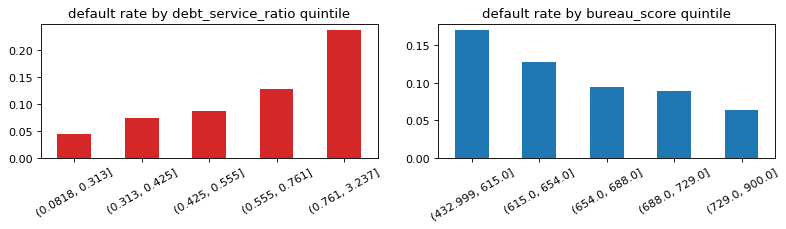

In [7]:
## 12. Visualise: default rate rises with the debt-service ratio and falls with bureau score
tmp = tr.assign(dsr_band=pd.qcut(tr.debt_service_ratio, 5), bureau_band=pd.qcut(tr.bureau_score, 5))
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
tmp.groupby("dsr_band", observed=True).default_12m.mean().plot.bar(ax=ax[0], color="tab:red"); ax[0].set_title("default rate by debt_service_ratio quintile")
tmp.groupby("bureau_band", observed=True).default_12m.mean().plot.bar(ax=ax[1], color="tab:blue"); ax[1].set_title("default rate by bureau_score quintile")
for x in ax: x.set_xlabel(""); x.tick_params(axis="x", labelrotation=30)
plt.tight_layout(); plt.show()

In [8]:
## 13. Models: the scorecard (logistic regression) vs gradient boosting - fit on TRAIN only
pipe = build_pipeline(selected, "logreg", 0.5).fit(tr[selected], tr.default_12m)
gb = build_pipeline(selected, "hgb").fit(tr[selected], tr.default_12m)
p_lr, p_gb = pipe.predict_proba(te[selected])[:, 1], gb.predict_proba(te[selected])[:, 1]
pd.DataFrame({"scorecard (LR)": credit_metrics(te.default_12m, p_lr), "boosting (HGB)": credit_metrics(te.default_12m, p_gb)}).T

                roc_auc    gini  ks_stat  pr_auc  recall_at_80_approval   brier       n  default_rate
scorecard (LR)   0.7683  0.5365   0.4394  0.3305                  0.515  0.0869  1800.0        0.1111
boosting (HGB)   0.7596  0.5192   0.4263  0.3097                  0.480  0.0887  1800.0        0.1111

In [9]:
## 14. Evaluation: calibration and the money view (stated assumptions: LGD 60%, margin 8%, decline the riskiest 20%)
print(calibration_table(te.default_12m, p_lr, bins=5).to_string(index=False))
print("\nbusiness view:", business_view(te.loan_amount, te.default_12m, p_lr))

bin   n  mean_predicted_pd  observed_default_rate
  1 360             0.0232                 0.0333
  2 360             0.0470                 0.0306
  3 360             0.0763                 0.0694
  4 360             0.1247                 0.1361
  5 360             0.2957                 0.2861

business view: {'approval_rate': 0.8, 'declined': 360, 'defaulters_declined': 103, 'good_customers_declined': 257, 'expected_loss_without_model': 51670200, 'loss_avoided': 31285200, 'margin_lost': 8931920, 'net_benefit': 22353280}


In [10]:
## 15. Interpretation: coefficients and REASON CODES for one declined-looking applicant
print(standardized_coefficients(pipe, selected).head(6).to_string(index=False))
worst = te.assign(pd_=p_lr).sort_values("pd_").iloc[[-1]]
print("\nhighest-risk test applicant: PD =", round(float(worst.pd_.iloc[0]), 3), "->", P.risk_level(float(worst.pd_.iloc[0])))
for rc in reason_codes(pipe, worst[selected], selected, top_k=3)[0]:
    print(f"  {rc['feature']:22s} {rc['contribution']:+.2f}  {rc['reason']}")

                  encoded      coef              feature  abs_coef
num__debt_to_income_ratio  0.569137 debt_to_income_ratio  0.569137
      num__loan_to_income  0.420389       loan_to_income  0.420389
num__credit_history_years -0.357311 credit_history_years  0.357311
        num__bureau_score -0.340603         bureau_score  0.340603
          num__log_income -0.334464           log_income  0.334464
      num__existing_loans  0.192530       existing_loans  0.192530

highest-risk test applicant: PD = 0.908 -> HIGH
  loan_to_income         +1.69  The loan amount is large relative to annual income (1.56x)
  debt_to_income_ratio   +1.62  Monthly debt payments are high relative to income (DTI 87%)
  existing_loans         +0.53  Number of existing loans is high (4)


In [11]:
## 16. Fairness (gender is NOT a model input; we only audit outcomes by gender). Decline the riskiest 20%.
cut = np.quantile(p_lr, 0.80)
t = group_table(te.gender, te.default_12m, p_lr > cut)
print(t.to_string(index=False))
print("adverse impact ratio (lowest / highest approval rate):", round(adverse_impact_ratio(t.approval_rate), 3), "(four-fifths rule: >= 0.80)")

 group    n  approval_rate  default_rate  approved_among_repaid
female  693         0.7864        0.1299                 0.8408
  male 1107         0.8085        0.0994                 0.8385
adverse impact ratio (lowest / highest approval rate): 0.973 (four-fifths rule: >= 0.80)


In [12]:
## 17. Drift: economic downturn batch vs training reference (KS test, H0: same distribution, alpha = 0.05)
ref = pd.read_csv("data/processed/reference.csv")
normal = engineer(pd.read_csv("data/production/batch_normal.csv"))
drifted = engineer(pd.read_csv("data/production/batch_drifted.csv"))
for name, batch in (("normal", normal), ("drifted", drifted)):
    print(f"--- {name} batch ({len(batch)} rows)")
    rep = ks_drift_report(ref, batch, P.DRIFT_FEATURES)[["feature", "ks_statistic", "p_value", "status"]]
    print(rep.assign(ks_statistic=rep.ks_statistic.round(4), p_value=rep.p_value.map("{:.1e}".format)).to_string(index=False))

--- normal batch (3000 rows)
             feature  ks_statistic p_value                status
      monthly_income        0.0333 7.1e-02  no_evidence_of_drift
          log_income        0.0322 1.3e-01  no_evidence_of_drift
      loan_to_income        0.0157 9.0e-01  no_evidence_of_drift
debt_to_income_ratio        0.0193 6.3e-01  no_evidence_of_drift
       emi_to_income        0.0243 3.4e-01  no_evidence_of_drift
credit_history_years        0.0490 1.5e-03 significant_but_small
        bureau_score        0.0333 9.0e-02  no_evidence_of_drift
--- drifted batch (3000 rows)
             feature  ks_statistic p_value                status
      monthly_income        0.1797 1.1e-42                 drift
          log_income        0.2011 5.6e-47                 drift
      loan_to_income        0.0178 7.9e-01  no_evidence_of_drift
debt_to_income_ratio        0.1590 1.7e-33                 drift
       emi_to_income        0.0150 8.9e-01  no_evidence_of_drift
credit_history_years        0.0

## 18. Common mistakes
* Fitting the imputer / scaler on **all** data before splitting (test statistics leak into training).
* Random split of applications: the same person appears in train and test (7% repeat applicants here).
* Using `interest_rate_offered`, collections or payment columns: information from the **future**.
* Treating `gender` or a fine-grained `location` as "just another feature" - a **policy and legal** question, not a technical one.
* "Drift detected, so retrain." Drift is evidence to **investigate**; labels arrive 12 months later, so performance is unknown at first.
* Reading a high p-value on 3,000 rows as "no change" or a tiny p-value as "important": always look at the size of D too.

## 19. Industry connection
Data engineer: *can we reliably get income and bureau data?* Data scientist: *which features carry signal?* ML engineer: *does the API
score exactly like training?* Risk and compliance: *can we explain, audit and defend each decision?* This repo's `src/governance/`
generates the model review pack and a GO / NO-GO gate that blocks a model with an unapproved feature, an adverse impact ratio below 0.8 or no reason codes.

## 20. Exercises
1. Change `assumed_annual_rate_pct` in `configs/params.yaml` to 18 and rerun section 10: which features change and which do not?
2. In section 8 add `age` to `honest`. How much does AUC move? Why can a *small* gain still not justify using it (policy)?
3. Move the decline rate in section 16 from 20% to 30%. Does the adverse impact ratio improve or get worse? Why?
4. In section 17 take only the first 200 rows of the drifted batch: what happens to the p-values and to D? 

## 21. Key takeaways
* Raw data + domain knowledge -> meaningful features; each one must be explainable and available at prediction time.
* A leaky column can turn an AUC of ~0.76 into ~0.95: **suspicious excellence is a bug**.
* In regulated lending the simple, auditable scorecard is the default; boosting is a monitored challenger.
* Governance (registry, fairness audit, review gate) is part of the pipeline, not paperwork after it.
* Drift is a signal; the decision to retrain needs data quality, labelled performance and business impact - and a human sign-off.